# 02 · Benchmark report and serving walkthrough

This notebook **does not train anything**. It reads the artifacts written by `python -m bnpl_risk.train`
(`reports/results.json`, `models/*.joblib`, `models/model_meta.json`), so the numbers shown here are exactly
the ones in `reports/benchmark.md`, the README, and the web demo.

It replaces the old notebooks 02–04: model comparison, interactive inference, and batch inference.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from bnpl_risk.config import (CATEGORICAL_COLS, CLASSES, NUMERIC_COLS, REPORTS_DIR,
                              MODELS_DIR, SPLIT_PATH, TARGET_COL)
from bnpl_risk.reporting import SERIES, _style
from bnpl_risk.seed import seed_everything

seed_everything()
_style()
pd.set_option("display.precision", 4)
results = json.loads((REPORTS_DIR / "results.json").read_text())
meta = json.loads((MODELS_DIR / "model_meta.json").read_text())
NAMES = {"logreg": "Logistic regression", "xgboost": "XGBoost", "resnet": "Tabular ResNet"}
print("selected model:", meta["model"])

selected model: {'family': 'logreg', 'params': {'C': 4.328761, 'class_weight': None}, 'calibration': 'temperature'}


## 1. Cross-validated comparison (identical folds, equal tuning budget)

In [2]:
keys = ["log_loss", "brier", "macro_f1", "roc_auc_macro", "pr_auc_High", "recall_High", "precision_High"]
cv = pd.DataFrame({NAMES[f]: {k: f"{v[k]['mean']:.4f} ± {v[k]['std']:.4f}" for k in keys}
                   for f, v in results["cv"].items()}).T
cv

,log_loss,brier,macro_f1,roc_auc_macro,pr_auc_High,recall_High,precision_High
Logistic regression,0.0690 ± 0.0076,0.0414 ± 0.0057,0.9003 ± 0.0178,0.9949 ± 0.0011,0.9801 ± 0.0070,0.9104 ± 0.0410,0.9282 ± 0.0259
XGBoost,0.0712 ± 0.0074,0.0423 ± 0.0051,0.8937 ± 0.0201,0.9945 ± 0.0012,0.9772 ± 0.0092,0.8872 ± 0.0384,0.9411 ± 0.0283
Tabular ResNet,0.0764 ± 0.0092,0.0445 ± 0.0060,0.8909 ± 0.0159,0.9942 ± 0.0013,0.9788 ± 0.0103,0.9264 ± 0.0283,0.9044 ± 0.0438


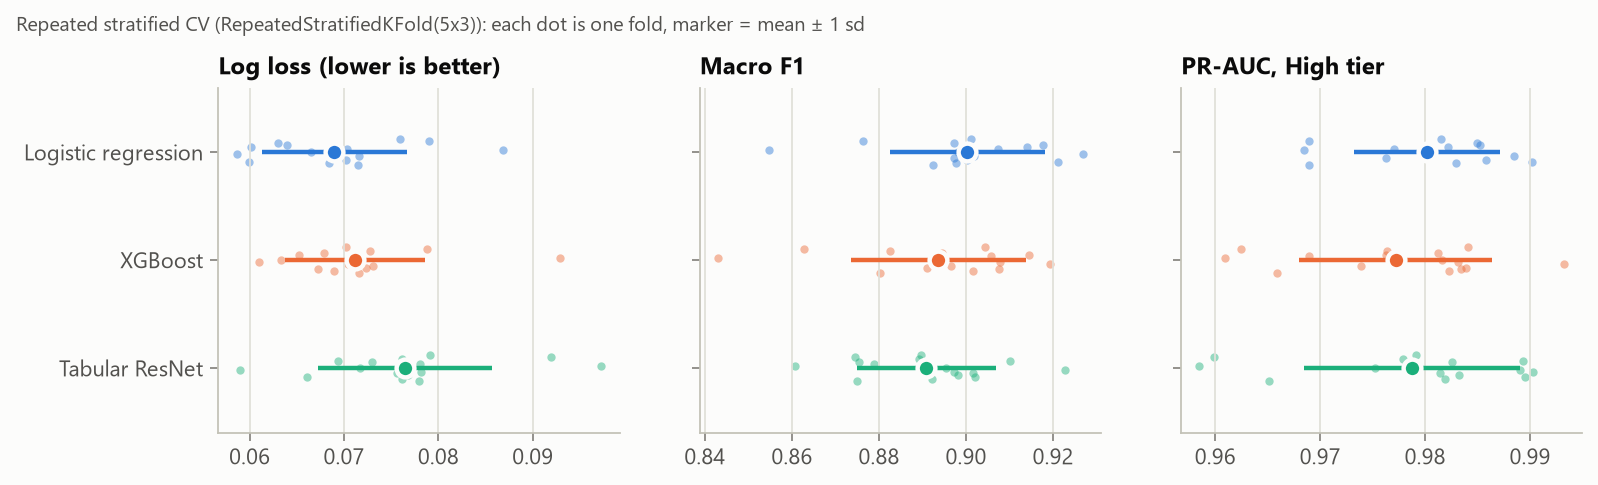

In [3]:
Image(filename=str(REPORTS_DIR / "figures" / "cv_benchmark.png"))

In [4]:
cmp = pd.DataFrame(results["comparisons"])
cmp["a"] = cmp["a"].map(lambda s: NAMES.get(s, s))
cmp["b"] = cmp["b"].map(lambda s: NAMES.get(s, s))
cmp.style.format({"mean_diff": "{:+.4f}", "t": "{:.2f}", "p": "{:.3f}"})

,a,b,metric,mean_diff,t,p
0,Logistic regression,XGBoost,log_loss,-0.0022,-0.95,0.359
1,Logistic regression,XGBoost,macro_f1,+0.0066,1.11,0.284
2,Logistic regression,XGBoost,brier,-0.0009,-0.63,0.540
3,Logistic regression,XGBoost,pr_auc_High,+0.0030,1.23,0.239
4,Logistic regression,Tabular ResNet,log_loss,-0.0074,-3.64,0.003
5,Logistic regression,Tabular ResNet,macro_f1,+0.0094,1.38,0.188
6,Logistic regression,Tabular ResNet,brier,-0.0031,-2.22,0.044
7,Logistic regression,Tabular ResNet,pr_auc_High,+0.0014,0.47,0.642
8,XGBoost,Tabular ResNet,log_loss,-0.0053,-2.33,0.035
9,XGBoost,Tabular ResNet,macro_f1,+0.0028,0.29,0.774


In [5]:
sel = results["selection"]
Markdown(f"**Selection:** {sel['rule']}. Best by log loss: {NAMES[sel['best_by_log_loss']]}; eligible within "
         f"1 SE: {', '.join(NAMES[e] for e in sel['eligible'])}, so **{NAMES[sel['selected']]}** is deployed.")

**Selection:** lowest mean CV log loss; simplest family within 1 corrected SE of the best. Best by log loss: Logistic regression; eligible within 1 SE: Logistic regression, XGBoost, so **Logistic regression** is deployed.

## 2. The original 0.84 vs 0.75 claim, replicated leak-free

In [6]:
abl = results["ablations"]
rows = {
    "Original XGBoost config, numeric only (as in the old notebook)": abl["legacy_xgb/numeric_only"],
    "Original XGBoost config, with categoricals": abl["legacy_xgb/with_categoricals"],
    "Tuned XGBoost (this project)": results["cv"]["xgboost"],
    "Tuned tabular ResNet (this project)": results["cv"]["resnet"],
}
pd.DataFrame({k: {"macro F1": f"{v['macro_f1']['mean']:.3f} ± {v['macro_f1']['std']:.3f}"} for k, v in rows.items()}).T

,macro F1
"Original XGBoost config, numeric only (as in the old notebook)",0.792 ± 0.019
"Original XGBoost config, with categoricals",0.886 ± 0.016
Tuned XGBoost (this project),0.894 ± 0.020
Tuned tabular ResNet (this project),0.891 ± 0.016


## 3. Held-out test set (scored once)

In [7]:
tm = {}
for f, t in results["test"].items():
    tm[NAMES[f]] = {k: f"{t['calibrated'][k]:.3f} [{t['ci95'][k][0]:.3f}, {t['ci95'][k][1]:.3f}]"
                    for k in ["macro_f1", "log_loss", "brier", "pr_auc_High", "recall_High", "ece_High"]}
pd.DataFrame(tm).T

,macro_f1,log_loss,brier,pr_auc_High,recall_High,ece_High
Logistic regression,"0.885 [0.859, 0.909]","0.079 [0.065, 0.095]","0.046 [0.038, 0.056]","0.983 [0.966, 0.994]","0.885 [0.827, 0.942]","0.003 [0.000, 0.005]"
XGBoost,"0.884 [0.855, 0.910]","0.079 [0.066, 0.095]","0.047 [0.039, 0.057]","0.982 [0.965, 0.993]","0.837 [0.760, 0.904]","0.005 [0.002, 0.008]"
Tabular ResNet,"0.888 [0.861, 0.914]","0.082 [0.067, 0.099]","0.047 [0.039, 0.057]","0.983 [0.969, 0.994]","0.875 [0.808, 0.942]","0.005 [0.002, 0.008]"


## 4. Calibration

In [8]:
pd.DataFrame({(NAMES[f], m): v for f, c in results["calibration"].items() for m, v in c["oof"].items()}).T

brier  log_loss  ece_Low  ece_Medium  \
Logistic regression none         0.0411    0.0684   0.0011      0.0031   
                    sigmoid      0.0752    0.1460   0.0463      0.0542   
                    isotonic     0.0694    0.1401   0.0309      0.0360   
                    temperature  0.0410    0.0683   0.0014      0.0015   
XGBoost             none         0.0424    0.0710   0.0020      0.0015   
                    sigmoid      0.0467    0.0946   0.0180      0.0107   
                    isotonic     0.0428    0.0818   0.0009      0.0026   
                    temperature  0.0424    0.0707   0.0021      0.0014   
Tabular ResNet      none         0.0458    0.0779   0.0062      0.0058   
                    sigmoid      0.0489    0.1003   0.0126      0.0140   
                    isotonic     0.0458    0.0836   0.0061      0.0045   
                    temperature  0.0457    0.0779   0.0065      0.0057   

                                 ece_High  macro_f1  
Logistic regression none           0.0003    0.9014  
                    sigmoid        0.0104    0.7352  
                    isotonic       0.0059    0.7840  
                    temperature    0.0005    0.9014  
XGBoost             none           0.0008    0.8918  
                    sigmoid        0.0062    0.8901  
                    isotonic       0.0005    0.8899  
                    temperature    0.0008    0.8918  
Tabular ResNet      none           0.0035    0.8876  
                    sigmoid        0.0034    0.8872  
                    isotonic       0.0017    0.8865  
                    temperature    0.0036    0.8876

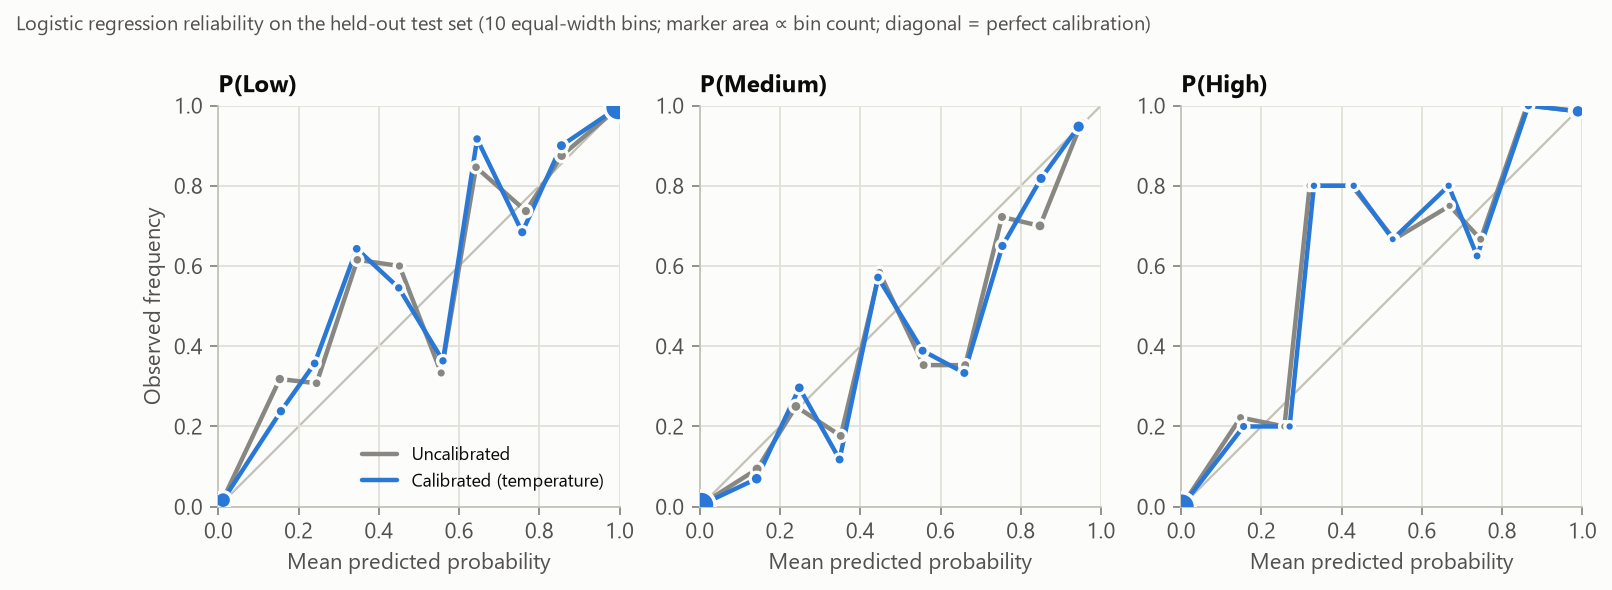

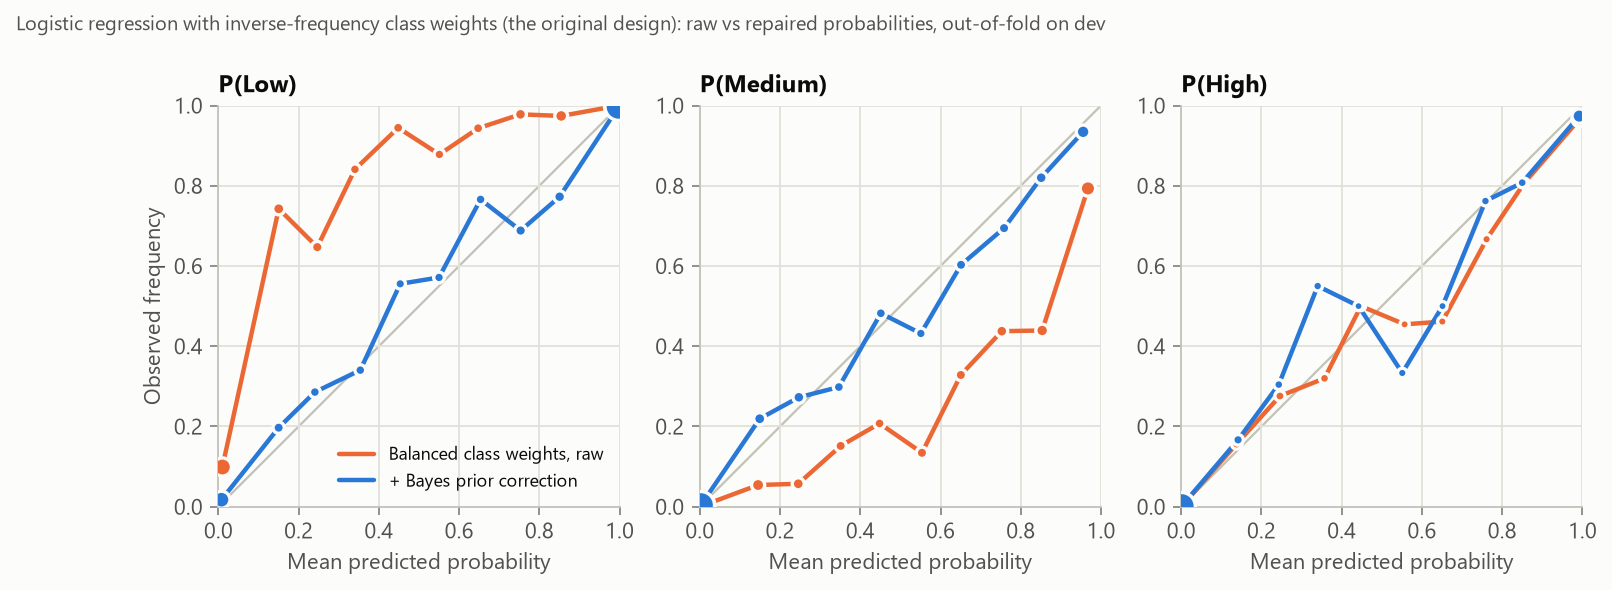

In [9]:
display(Image(filename=str(REPORTS_DIR / "figures" / "reliability.png")))
display(Image(filename=str(REPORTS_DIR / "figures" / "calibration_weighted.png")))

## 5. Decisions under explicit unit economics

In [10]:
rows = {NAMES[f]: results["decisions"][f]["test"] for f in NAMES}
rows.update({"Approve everyone": results["decisions"]["reference"]["approve_all"],
             "Oracle": results["decisions"]["reference"]["oracle"]})
cols = ["approval_rate", "high_rate_approved", "medhigh_rate_approved", "high_captured",
        "profit_per_applicant", "misclassification_cost_argmax", "misclassification_cost_bayes"]
pd.DataFrame(rows).T[cols].astype(float).style.format("{:.4f}")

,approval_rate,high_rate_approved,medhigh_rate_approved,high_captured,profit_per_applicant,misclassification_cost_argmax,misclassification_cost_bayes
Logistic regression,0.8490,0.0000,0.0047,1.0000,6.1974,0.0950,0.0645
XGBoost,0.8495,0.0000,0.0053,1.0000,6.1972,0.0980,0.0765
Tabular ResNet,0.8690,0.0000,0.0098,1.0000,6.1729,0.0925,0.0710
Approve everyone,1.0000,0.0520,0.1200,0.0000,-1.6472,0.0000,0.0000
Oracle,0.8800,0.0000,0.0000,1.0000,6.5563,0.0000,0.0000


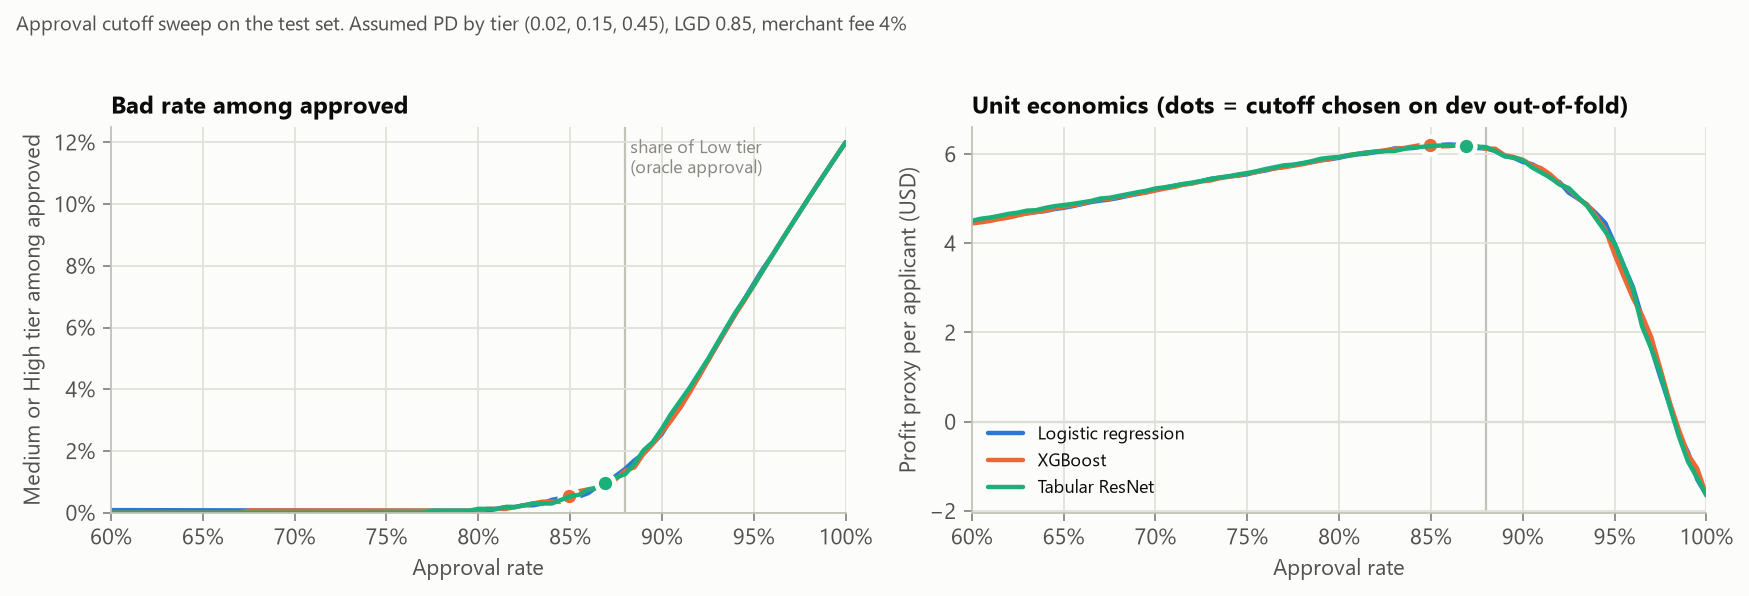

In [11]:
Image(filename=str(REPORTS_DIR / "figures" / "cost_curve.png"))

## 6. Drivers

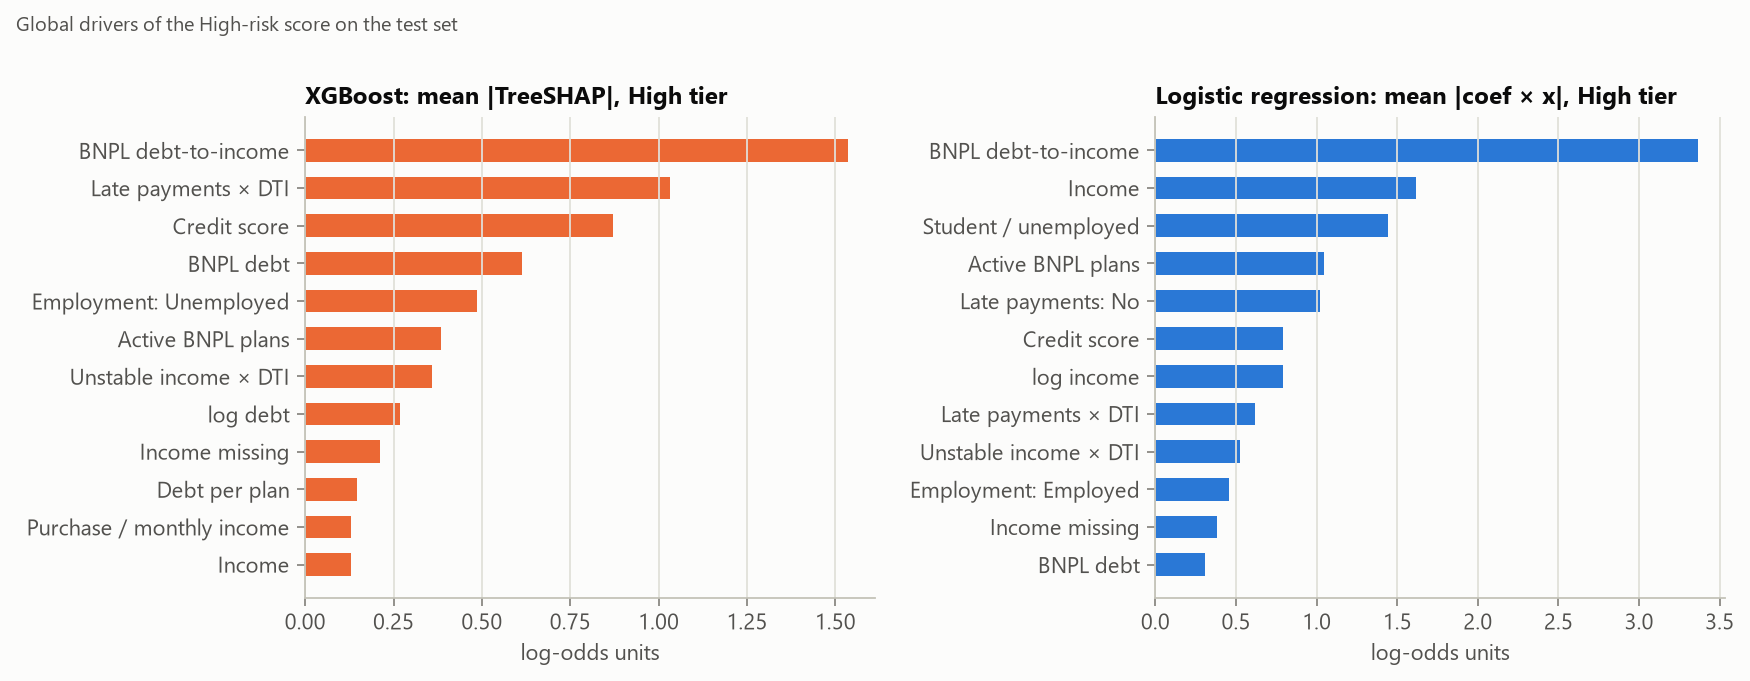

In [12]:
Image(filename=str(REPORTS_DIR / "figures" / "importance.png"))

## 7. Serving: one object for single records and batches

`RiskScorer` loads the exact fitted pipeline evaluated above. Inputs are validated against the schema;
invalid rows are rejected with a reason, and values outside the training support are flagged.

In [13]:
from bnpl_risk.inference import RiskScorer

scorer = RiskScorer.load()
applicant = {"Age": 22, "Income_USD": 14000, "Credit_Score": 610, "Total_BNPL_Active_Loans": 4,
             "Total_BNPL_Debt_USD": 650, "Average_Transaction_Value_USD": 380,
             "Employment_Status": "Student", "Late_Payment_History": "No",
             "Shopping_Category_Most_Frequent": "Electronics"}
scorer.score_one(applicant)

{'probabilities': {'Low': 0.08790511766995618,
  'Medium': 0.896542229714867,
  'High': 0.015552652615176913},
 'expected_pd': 0.1432381304874588,
 'expected_loss_usd': 46.26591614744919,
 'risk_tier': 'Medium',
 'decision': 'DECLINE',
 'out_of_distribution': []}

In [14]:
from bnpl_risk.config import DATA_PATH

batch = pd.read_csv(DATA_PATH).drop(columns=[TARGET_COL]).head(6)
batch.loc[1, "Employment_Status"] = "Astronaut"       # unknown category -> rejected
batch.loc[2, "Total_BNPL_Debt_USD"] = 23_500          # the old README demo value -> flagged
batch.loc[3, "Income_USD"] = np.nan                   # missing income -> imputed like training
scorer.score(batch)[["Customer_ID", "Prob_Low", "Prob_Medium", "Prob_High", "Expected_PD",
                     "Decision", "Risk_Tier", "OOD_Flags", "Errors"]]

,Customer_ID,Prob_Low,Prob_Medium,Prob_High,Expected_PD,Decision,Risk_Tier,OOD_Flags,Errors
0,C00001,1.0000e+00,3.5151e-06,2.6862e-13,0.0200,APPROVE,Low,,
1,C00002,NaN,NaN,NaN,NaN,REJECTED_INPUT,NaN,,Employment_Status='Astronaut' not in ['Employe...
2,C00003,4.1310e-76,8.7274e-47,1.0000e+00,0.4500,DECLINE,High,Total_BNPL_Debt_USD,
3,C00004,9.9983e-01,1.6786e-04,3.6078e-08,0.0200,APPROVE,Low,,
4,C00005,9.9992e-01,7.9251e-05,9.3917e-11,0.0200,APPROVE,Low,,
5,C00006,2.1498e-02,9.6623e-01,1.2271e-02,0.1509,DECLINE,Medium,,
